# Tyre degradation — grip(age) = 1 − a·age^b per compound (T5 groundwork)

The fitter never sees raw lap times. It works on the joint fit's *partial residuals*:
lap time with session, driver, compound, fuel and evolution removed and only the age
contribution added back, so the power law cannot re-absorb what E-10 already
explained. In/out laps and inaccurate laps are refused outright — an in-lap in a
degradation dataset is a cleaning failure wearing a physics costume (E-09).

A fit at the lower bound (a = 0) is a finding, not a failure: that circuit-era-compound
showed no measurable degradation signal, and the sample-size flags say how much weight
the claim can carry.

In [1]:
import pandas as pd

from senna import config
from senna.data.db import database_url, engine_for
from senna.physics.fits import frames, plots
from senna.physics.fits.gate import assert_quality_reports

fits_cfg = config.load("fits")
ingest_cfg = config.load("ingest")
CALIB = config.get(config.load("data_split"), "calibration_rounds")
SLICKS = ("SOFT", "MEDIUM", "HARD")

assert_quality_reports(
    config.get(ingest_cfg, "seasons"),
    config.REPO_ROOT / config.get(ingest_cfg, "quality.report_dir"),
)
engine = engine_for(database_url())
conn = await engine.connect()
index = await frames.circuit_index(conn, CALIB)
index[["slug", "era"]].drop_duplicates().groupby("era").size()

era
2024    25
2026     6
dtype: int64

In [2]:
excluded_rows = []
for era in sorted(index["era"].unique()):
    for slug in sorted(index.loc[index["era"] == era, "slug"].unique()):
        event_name = index.loc[index["slug"] == slug, "event_name"].iloc[0]
        laps = await frames.pace_laps(conn, event_name, era, CALIB)
        if laps.empty:
            continue
        in_out = (laps["pit_in_time_s"].notna() | laps["pit_out_time_s"].notna()).sum()
        excluded_rows.append(
            {
                "circuit": slug,
                "era": era,
                "rows": len(laps),
                "in_out_excluded": int(in_out),
                "inaccurate_excluded": int((~laps["is_accurate"].astype(bool)).sum()),
                "non_green_excluded": int((~laps["is_green"].astype(bool)).sum()),
            }
        )
excluded = pd.DataFrame(excluded_rows)
excluded.sum(numeric_only=True).to_frame("total").T

,rows,in_out_excluded,inaccurate_excluded,non_green_excluded
total,59107,3371,7383,5324


Per-fit exclusion counts — the E-09 reporting clause. Full table below.

In [3]:
excluded

,circuit,era,rows,in_out_excluded,inaccurate_excluded,non_green_excluded
0,abu_dhabi_grand_prix,2024,3348,184,282,102
1,australian_grand_prix,2024,998,74,141,61
2,austrian_grand_prix,2024,1586,66,136,69
3,azerbaijan_grand_prix,2024,1941,89,205,203
4,bahrain_grand_prix,2024,2257,170,281,122
5,belgian_grand_prix,2024,1138,72,111,19
6,british_grand_prix,2024,971,50,169,125
7,chinese_grand_prix,2024,2855,139,384,297
8,dutch_grand_prix,2024,2790,133,395,316
9,emilia_romagna_grand_prix,2024,2445,130,325,221


In [4]:
from senna.physics.fits.degradation import fit_degradation
from senna.physics.fits.fuel import session_fuel
from senna.physics.fits.joint_pace import age_partial_residuals, fit_joint_pace

deg_cfg = config.get(fits_cfg, "degradation")
bounds = (
    [deg_cfg["curve_bounds"]["a"][0], deg_cfg["curve_bounds"]["b"][0]],
    [deg_cfg["curve_bounds"]["a"][1], deg_cfg["curve_bounds"]["b"][1]],
)
VIF_MAX = config.get(fits_cfg, "joint_pace.vif_max")
SC_BURN = config.get(fits_cfg, "fuel.sc_burn_factor")
fuel_by_era = {
    era: config.get(config.load(f"physics_{era}"), "mass.race_fuel_kg")
    for era in sorted(index["era"].unique())
}

deg_rows, residual_cache = [], {}
for era, allowance_kg in fuel_by_era.items():
    for slug in sorted(index.loc[index["era"] == era, "slug"].unique()):
        event_name = index.loc[index["slug"] == slug, "event_name"].iloc[0]
        laps = await frames.pace_laps(conn, event_name, era, CALIB)
        if laps.empty:
            continue
        laps = laps[laps["compound"].isin(SLICKS)]
        fuel_kg = session_fuel(laps, allowance_kg, SC_BURN)
        fit = fit_joint_pace(laps, fuel_kg, vif_max=VIF_MAX, calibration_rounds=CALIB)
        residuals = age_partial_residuals(laps, fuel_kg, calibration_rounds=CALIB)
        residual_cache[(slug, era)] = (residuals, fit.t0_s)
        for compound, deg in fit_degradation(
            residuals,
            fit.t0_s,
            bounds=bounds,
            min_laps=deg_cfg["min_laps"],
            min_stints=deg_cfg["min_stints"],
            min_drivers=deg_cfg["min_drivers"],
            min_max_age=deg_cfg["min_max_age"],
        ).items():
            deg_rows.append(
                {
                    "circuit": slug,
                    "era": era,
                    "compound": compound,
                    "a": deg.a,
                    "b": deg.b,
                    "n_laps": deg.n_laps,
                    "max_age_seen": deg.max_age_seen,
                    "low_confidence": deg.low_confidence,
                }
            )
deg_table = pd.DataFrame(deg_rows)
deg_table

,circuit,era,compound,a,b,n_laps,max_age_seen,low_confidence
0,abu_dhabi_grand_prix,2024,HARD,9.084357e-04,0.879288,2091,45,False
1,abu_dhabi_grand_prix,2024,MEDIUM,4.362551e-04,1.216977,896,28,False
2,abu_dhabi_grand_prix,2024,SOFT,6.210481e-05,1.997957,41,24,False
3,australian_grand_prix,2024,HARD,1.381506e-05,2.086781,692,36,False
4,australian_grand_prix,2024,MEDIUM,5.286615e-05,1.905456,148,24,False
...,...,...,...,...,...,...,...,...
80,miami_grand_prix,2026,MEDIUM,1.870006e-04,1.574745,286,25,False
81,miami_grand_prix,2026,SOFT,4.476372e-17,0.300000,36,19,True
82,monaco_grand_prix,2026,HARD,3.269153e-06,2.371019,323,48,False
83,monaco_grand_prix,2026,MEDIUM,1.578124e-06,2.419485,600,57,False


/Users/saad/senna/docs/fits/degradation/bahrain_grand_prix_2024_HARD.png
/Users/saad/senna/docs/fits/degradation/bahrain_grand_prix_2024_MEDIUM.png
/Users/saad/senna/docs/fits/degradation/bahrain_grand_prix_2024_SOFT.png
/Users/saad/senna/docs/fits/degradation/japanese_grand_prix_2026_HARD.png
/Users/saad/senna/docs/fits/degradation/japanese_grand_prix_2026_MEDIUM.png


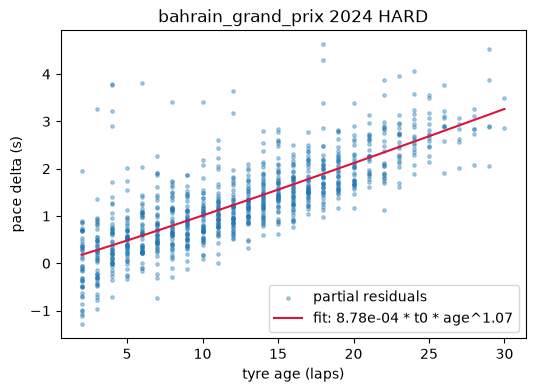

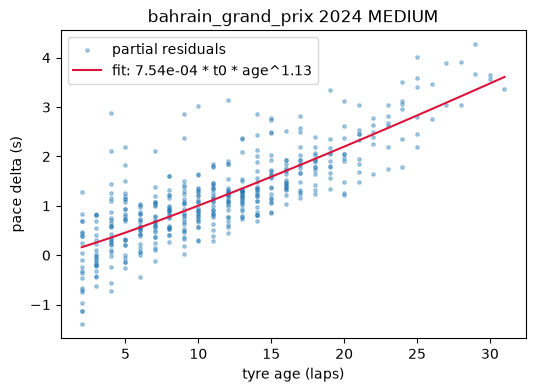

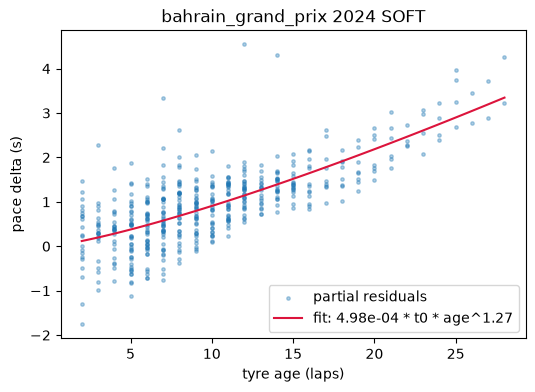

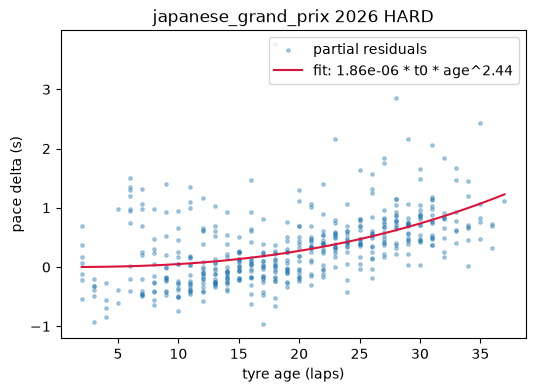

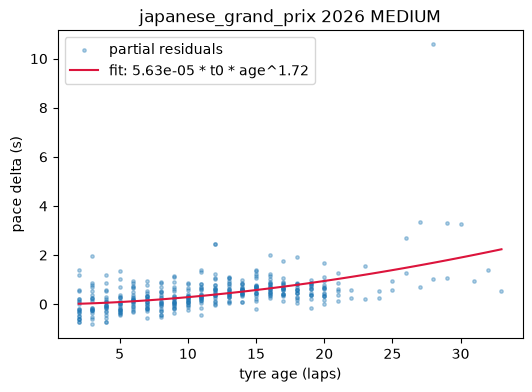

In [5]:
for slug, era in [("bahrain_grand_prix", "2024"), ("japanese_grand_prix", "2026")]:
    residuals, t0_s = residual_cache[(slug, era)]
    for compound in sorted(residuals["compound"].unique()):
        row = deg_table.query(
            "circuit == @slug and era == @era and compound == @compound"
        ).iloc[0]
        on_compound = residuals[residuals["compound"] == compound]
        fig = plots.degradation_curve(
            on_compound["tyre_life"],
            on_compound["pace_residual_s"],
            a=row["a"],
            b=row["b"],
            t0_s=t0_s,
            title=f"{slug} {era} {compound}",
        )
        print(plots.save_figure(fig, "degradation", f"{slug}_{era}_{compound}"))

Low-confidence fits stay in the yaml with their flags — T5's cluster transfer needs
the coefficients either way, and the flag travels with every consumer.

In [6]:
await conn.close()
await engine.dispose()